# Bonus — Predictive Model: Next-Day Trader Profitability

**Goal:** Predict whether a trader will be profitable the next day, and estimate PnL volatility, using:
- Current-day sentiment features (Fear/Greed score, classification)
- Current-day behavioral features (trade count, avg size, win rate, long ratio, volume)

Two tasks:
1. **Classification** — Predict next-day `pnl_positive` (profitable or not)
2. **Regression** — Predict next-day `|daily_pnl|` (PnL magnitude / volatility proxy)

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    mean_absolute_error, r2_score, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1d2e',
    'axes.edgecolor':   '#3a3d52',
    'axes.labelcolor':  '#e0e0e0',
    'xtick.color':      '#a0a0b0',
    'ytick.color':      '#a0a0b0',
    'text.color':       '#e0e0e0',
    'grid.color':       '#2a2d3e',
    'grid.alpha':       0.5,
    'font.family':      'DejaVu Sans',
    'font.size':        11,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'figure.dpi':       130,
})

CHARTS_DIR = Path('../charts')
CHARTS_DIR.mkdir(exist_ok=True)

def save(name):
    plt.savefig(CHARTS_DIR / f'{name}.png', bbox_inches='tight',
                facecolor=plt.rcParams['figure.facecolor'])
    plt.show()
    print(f'  ✔ saved → charts/{name}.png')

print('✅ Setup complete')

✅ Setup complete


## 1. Load & Rebuild Daily Dataset

> Re-runs the same data prep from the main notebook — kept self-contained so this notebook runs independently.

In [2]:
# ── Load raw data ────────────────────────────────────────────────────────────
fg = pd.read_csv('../data/fear_greed_index.csv')
hl = pd.read_csv('../data/historical_data.csv')

# ── Fear/Greed prep ──────────────────────────────────────────────────────────
fg['date'] = pd.to_datetime(fg['timestamp'], unit='s').dt.normalize()
fg = fg.sort_values('date').drop_duplicates('date', keep='last')
SENT_ORDER = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
fg['sentiment_score'] = pd.Categorical(fg['classification'],
                                        categories=SENT_ORDER, ordered=True).codes

# ── Trade data prep ──────────────────────────────────────────────────────────
hl['date'] = pd.to_datetime(hl['Timestamp IST'], dayfirst=True).dt.normalize()
hl['is_long'] = (hl['Direction'].str.strip().str.lower() == 'buy').astype(int)
hl['is_win']  = (hl['Closed PnL'] > 0).astype(int)
hl['is_close']= (hl['Closed PnL'] != 0).astype(int)

daily = (
    hl.groupby(['Account', 'date'])
    .agg(
        daily_pnl        = ('Closed PnL',   'sum'),
        trade_count      = ('Trade ID',      'count'),
        avg_size_usd     = ('Size USD',      'mean'),
        total_volume_usd = ('Size USD',      'sum'),
        wins             = ('is_win',        'sum'),
        closes           = ('is_close',      'sum'),
        long_trades      = ('is_long',       'sum'),
        total_fee        = ('Fee',           'sum'),
    )
    .reset_index()
)
daily['win_rate']   = np.where(daily['closes'] > 0, daily['wins'] / daily['closes'], np.nan)
daily['long_ratio'] = daily['long_trades'] / daily['trade_count']
daily['pnl_positive'] = (daily['daily_pnl'] > 0).astype(int)

daily = daily.merge(
    fg[['date', 'value', 'classification', 'sentiment_score']],
    on='date', how='inner'
)

print(f'Trader-day rows after merge: {len(daily):,}')
print(f'Unique traders: {daily.Account.nunique()}')
print(f'Date range: {daily.date.min().date()} → {daily.date.max().date()}')

Trader-day rows after merge: 2,340
Unique traders: 32
Date range: 2023-05-01 → 2025-05-01


## 2. Feature Engineering — Lag Features

For next-day prediction we need to **shift targets by 1 day per trader** so we're predicting tomorrow using today's features.

In [3]:
# ── Sort and create next-day targets per trader ──────────────────────────────
daily = daily.sort_values(['Account', 'date'])

daily['next_day_pnl_positive'] = daily.groupby('Account')['pnl_positive'].shift(-1)
daily['next_day_pnl']          = daily.groupby('Account')['daily_pnl'].shift(-1)
daily['next_day_pnl_abs']      = daily['next_day_pnl'].abs()  # volatility proxy

# ── Rolling features (3-day lookback per trader) ─────────────────────────────
for col in ['daily_pnl', 'win_rate', 'trade_count', 'long_ratio', 'avg_size_usd']:
    daily[f'{col}_roll3'] = (
        daily.groupby('Account')[col]
        .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
    )

# ── Streak feature: consecutive profitable days ───────────────────────────────
def profit_streak(series):
    streak = []
    s = 0
    for v in series:
        if v == 1:
            s += 1
        else:
            s = 0
        streak.append(s)
    return streak

daily['profit_streak'] = (
    daily.groupby('Account')['pnl_positive']
    .transform(profit_streak)
)

# ── Drop last row per trader (no next-day label) ──────────────────────────────
model_df = daily.dropna(subset=['next_day_pnl_positive', 'win_rate']).copy()

# ── Label encode sentiment classification ────────────────────────────────────
le = LabelEncoder()
model_df['sentiment_encoded'] = le.fit_transform(model_df['classification'])

print(f'Model-ready rows: {len(model_df):,}')
print(f'Class balance — profitable days: {model_df.next_day_pnl_positive.mean():.1%}')

Model-ready rows: 1,664
Class balance — profitable days: 69.7%


## 3. Feature Selection

In [4]:
FEATURES = [
    # Sentiment
    'sentiment_score',          # ordinal 0–4
    'value',                    # raw 0–100 index
    # Today's behavior
    'trade_count',
    'avg_size_usd',
    'total_volume_usd',
    'win_rate',
    'long_ratio',
    'total_fee',
    'daily_pnl',
    'pnl_positive',             # was today profitable?
    # 3-day rolling
    'daily_pnl_roll3',
    'win_rate_roll3',
    'trade_count_roll3',
    'long_ratio_roll3',
    'avg_size_usd_roll3',
    # Streak
    'profit_streak',
]

X = model_df[FEATURES].fillna(0)
y_clf = model_df['next_day_pnl_positive'].astype(int)
y_reg = np.log1p(model_df['next_day_pnl_abs'])  # log-transform for regression

print(f'Feature matrix: {X.shape}')
print(f'\nFeatures used:')
for i, f in enumerate(FEATURES, 1):
    print(f'  {i:2d}. {f}')

Feature matrix: (1664, 16)

Features used:
   1. sentiment_score
   2. value
   3. trade_count
   4. avg_size_usd
   5. total_volume_usd
   6. win_rate
   7. long_ratio
   8. total_fee
   9. daily_pnl
  10. pnl_positive
  11. daily_pnl_roll3
  12. win_rate_roll3
  13. trade_count_roll3
  14. long_ratio_roll3
  15. avg_size_usd_roll3
  16. profit_streak


## 4. Task 1 — Classification: Will Next Day Be Profitable?

Models compared:
- Logistic Regression (baseline)
- Gradient Boosting (primary)
- Random Forest (ensemble comparison)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# ── Models ───────────────────────────────────────────────────────────────────
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=500, class_weight='balanced', random_state=42))
    ]),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=6, class_weight='balanced', random_state=42
    ),
}

# ── Cross-validation ─────────────────────────────────────────────────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print('5-Fold CV AUC-ROC scores:')
print('-' * 50)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                              scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores
    print(f'  {name:<25} {scores.mean():.4f} ± {scores.std():.4f}')

print()
best_name = max(cv_results, key=lambda k: cv_results[k].mean())
print(f'  ✅ Best model: {best_name}')

5-Fold CV AUC-ROC scores:
--------------------------------------------------
  Logistic Regression       0.6682 ± 0.0255
  Gradient Boosting         0.6734 ± 0.0286
  Random Forest             0.6943 ± 0.0305

  ✅ Best model: Random Forest


In [6]:
# ── Train best model on full train set, evaluate on test ─────────────────────
best_clf = models[best_name]
best_clf.fit(X_train, y_train)
y_pred  = best_clf.predict(X_test)
y_proba = best_clf.predict_proba(X_test)[:, 1]

auc  = roc_auc_score(y_test, y_proba)
print(f'\n=== {best_name} — Test Set Results ===')
print(f'AUC-ROC: {auc:.4f}')
print()
print(classification_report(y_test, y_pred, target_names=['Unprofitable', 'Profitable']))


=== Random Forest — Test Set Results ===
AUC-ROC: 0.6787

              precision    recall  f1-score   support

Unprofitable       0.47      0.59      0.53       101
  Profitable       0.80      0.71      0.75       232

    accuracy                           0.68       333
   macro avg       0.64      0.65      0.64       333
weighted avg       0.70      0.68      0.68       333



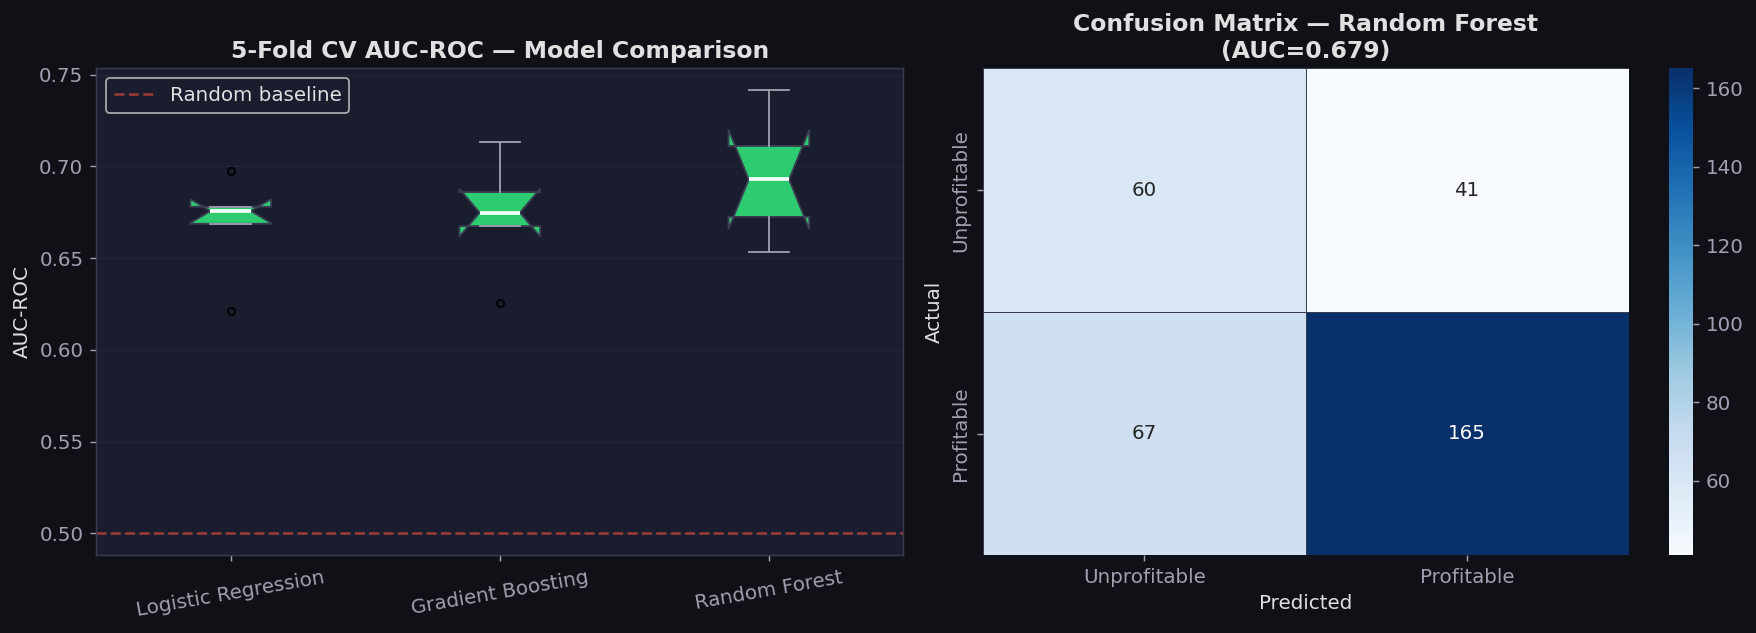

  ✔ saved → charts/bonus_clf_model_comparison.png


In [7]:
# ── Plot 1: CV comparison + Confusion Matrix ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CV boxplot
ax = axes[0]
data = [cv_results[k] for k in models]
bp = ax.boxplot(data, patch_artist=True, notch=True,
                 boxprops=dict(facecolor='#2ecc71', color='#3a3d52'),
                 medianprops=dict(color='white', linewidth=2),
                 whiskerprops=dict(color='#a0a0b0'),
                 capprops=dict(color='#a0a0b0'),
                 flierprops=dict(marker='o', color='#e74c3c', markersize=4))
ax.set_xticks(range(1, len(models)+1))
ax.set_xticklabels(models.keys(), rotation=10)
ax.set_ylabel('AUC-ROC')
ax.set_title('5-Fold CV AUC-ROC — Model Comparison')
ax.axhline(0.5, color='#e74c3c', linestyle='--', alpha=0.6, label='Random baseline')
ax.legend()
ax.grid(True, axis='y')

# Confusion matrix
ax2 = axes[1]
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Unprofitable', 'Profitable'],
            yticklabels=['Unprofitable', 'Profitable'],
            ax=ax2, linewidths=0.5, linecolor='#3a3d52')
ax2.set_title(f'Confusion Matrix — {best_name}\n(AUC={auc:.3f})')
ax2.set_xlabel('Predicted')
ax2.set_ylabel('Actual')

plt.tight_layout()
save('bonus_clf_model_comparison')

## 5. Feature Importance

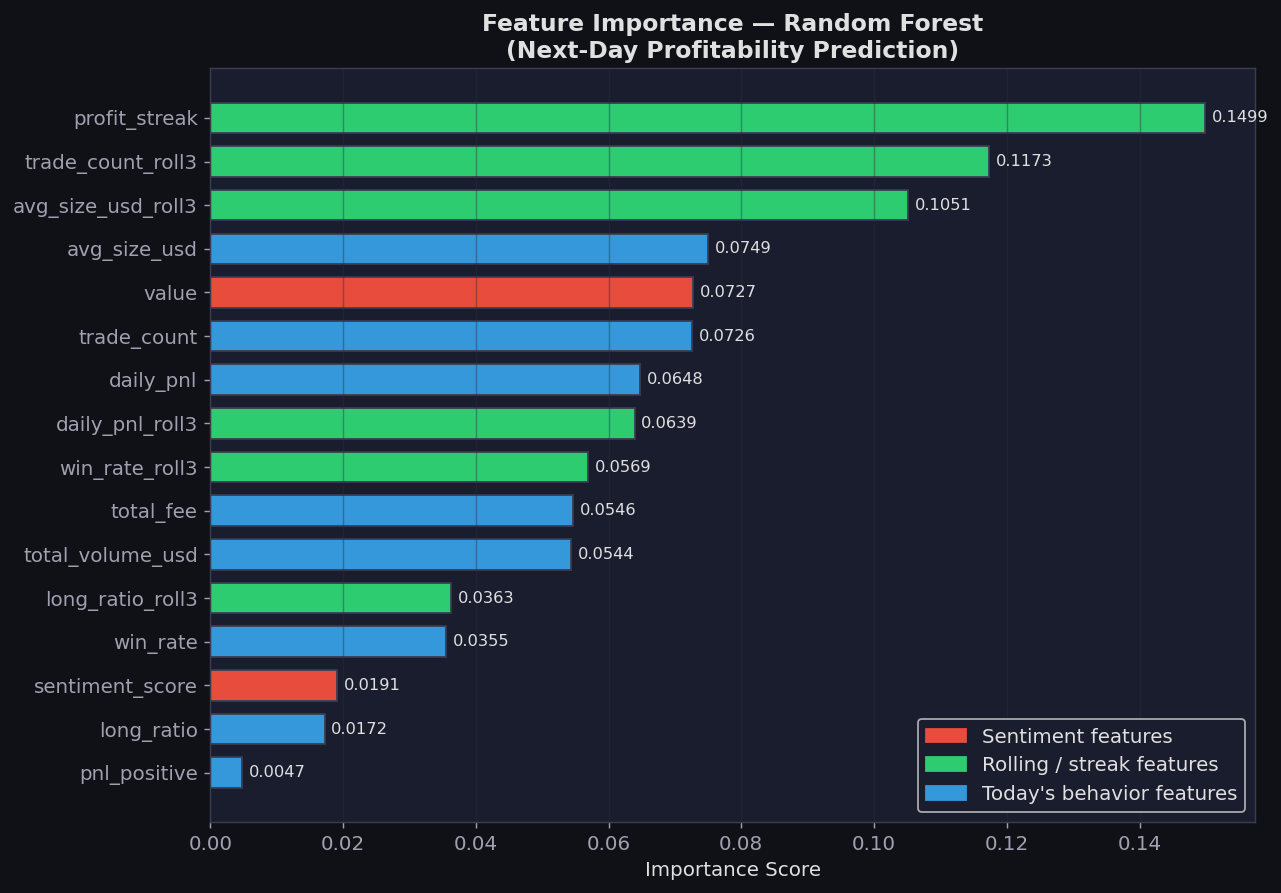

  ✔ saved → charts/bonus_feature_importance.png


In [8]:
# ── Extract feature importances from best model ───────────────────────────────
if hasattr(best_clf, 'feature_importances_'):
    importances = best_clf.feature_importances_
elif hasattr(best_clf, 'named_steps'):
    # Pipeline — use permutation importance
    r = permutation_importance(best_clf, X_test, y_test,
                                n_repeats=20, random_state=42, scoring='roc_auc')
    importances = r.importances_mean
else:
    importances = np.zeros(len(FEATURES))

feat_imp = pd.Series(importances, index=FEATURES).sort_values(ascending=True)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

colors = ['#e74c3c' if 'sentiment' in f or f == 'value' else
          '#2ecc71' if 'roll3' in f or 'streak' in f else
          '#3498db' for f in feat_imp.index]

bars = ax.barh(feat_imp.index, feat_imp.values, color=colors, edgecolor='#3a3d52', height=0.7)

# Value labels
for bar, val in zip(bars, feat_imp.values):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', ha='left', fontsize=9, color='#e0e0e0')

ax.set_title(f'Feature Importance — {best_name}\n(Next-Day Profitability Prediction)')
ax.set_xlabel('Importance Score')
ax.grid(True, axis='x', alpha=0.4)

# Legend
legend_patches = [
    mpatches.Patch(color='#e74c3c', label='Sentiment features'),
    mpatches.Patch(color='#2ecc71', label='Rolling / streak features'),
    mpatches.Patch(color='#3498db', label='Today\'s behavior features'),
]
ax.legend(handles=legend_patches, loc='lower right')

plt.tight_layout()
save('bonus_feature_importance')

## 6. Sentiment vs Model Accuracy

Does the model perform better in certain sentiment regimes?

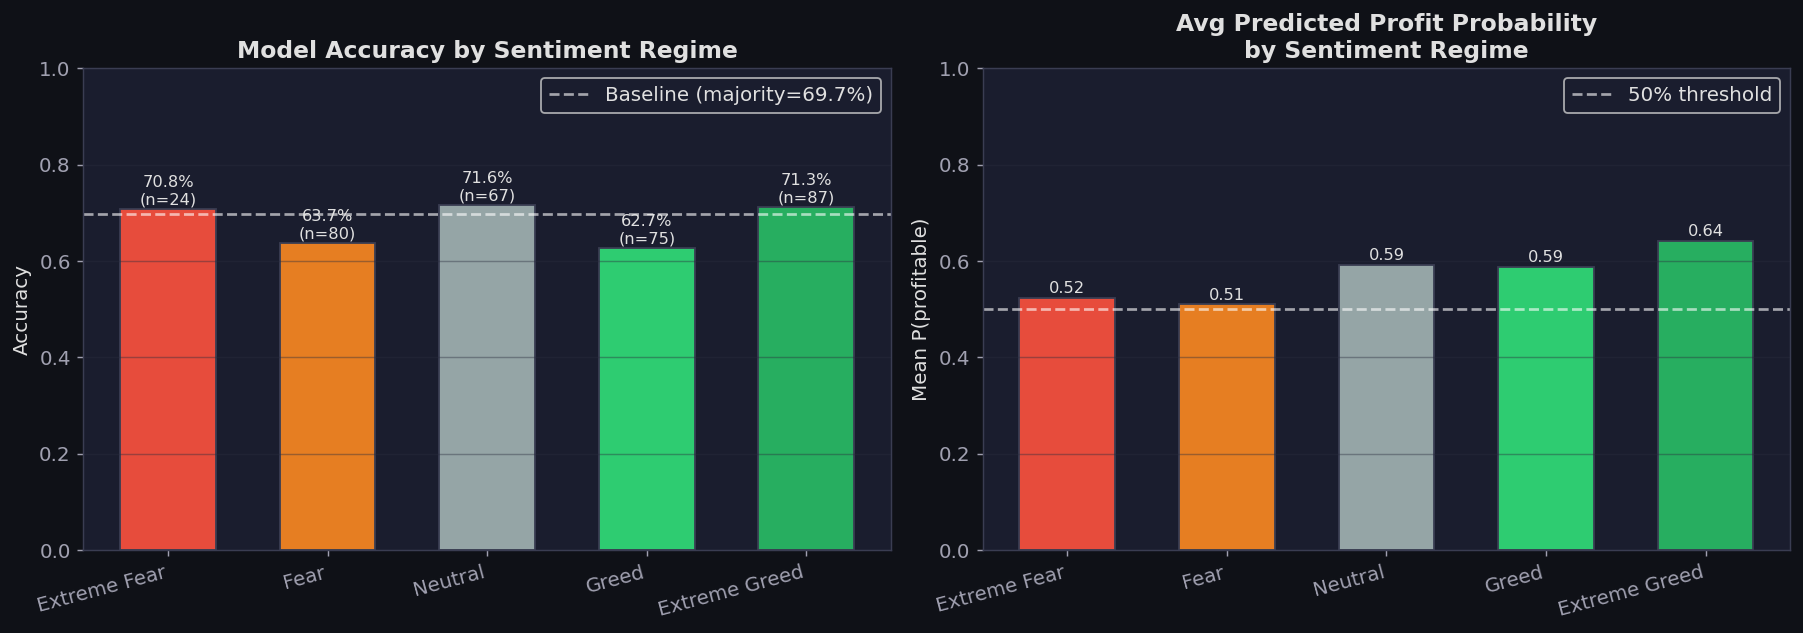

  ✔ saved → charts/bonus_accuracy_by_sentiment.png


In [9]:
# ── Accuracy by sentiment regime ─────────────────────────────────────────────
test_idx = X_test.index
test_eval = model_df.loc[test_idx].copy()
test_eval['predicted']   = y_pred
test_eval['correct']     = (test_eval['predicted'] == test_eval['next_day_pnl_positive']).astype(int)
test_eval['proba']       = y_proba

acc_by_sent = (
    test_eval.groupby('classification')
    .agg(accuracy=('correct', 'mean'), n=('correct', 'count'), auc_proxy=('proba', 'mean'))
    .reindex([s for s in ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
              if s in test_eval['classification'].unique()])
)

SENT_COLORS = {
    'Extreme Fear': '#e74c3c', 'Fear': '#e67e22',
    'Neutral': '#95a5a6', 'Greed': '#2ecc71', 'Extreme Greed': '#27ae60'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy by sentiment
ax = axes[0]
colors = [SENT_COLORS.get(s, '#aaa') for s in acc_by_sent.index]
bars = ax.bar(acc_by_sent.index, acc_by_sent['accuracy'], color=colors,
               edgecolor='#3a3d52', width=0.6)
for bar, val, n in zip(bars, acc_by_sent['accuracy'], acc_by_sent['n']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.1%}\n(n={n})', ha='center', fontsize=9)
ax.axhline(y_clf.mean(), color='white', linestyle='--', alpha=0.6, label=f'Baseline (majority={y_clf.mean():.1%})')
ax.set_title('Model Accuracy by Sentiment Regime')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(True, axis='y', alpha=0.4)
plt.setp(ax.get_xticklabels(), rotation=15, ha='right')

# Prediction confidence (mean proba) by sentiment
ax2 = axes[1]
bars2 = ax2.bar(acc_by_sent.index, acc_by_sent['auc_proxy'], color=colors,
                 edgecolor='#3a3d52', width=0.6)
ax2.axhline(0.5, color='white', linestyle='--', alpha=0.6, label='50% threshold')
for bar, val in zip(bars2, acc_by_sent['auc_proxy']):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.2f}', ha='center', fontsize=9)
ax2.set_title('Avg Predicted Profit Probability\nby Sentiment Regime')
ax2.set_ylabel('Mean P(profitable)')
ax2.set_ylim(0, 1.0)
ax2.legend()
ax2.grid(True, axis='y', alpha=0.4)
plt.setp(ax2.get_xticklabels(), rotation=15, ha='right')

plt.tight_layout()
save('bonus_accuracy_by_sentiment')

## 7. Task 2 — Regression: Predict Next-Day PnL Volatility

Target: `log(1 + |next_day_pnl|)` — predicts the magnitude of tomorrow's PnL swing.

In [10]:
from sklearn.ensemble import GradientBoostingRegressor

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

gbr = GradientBoostingRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, random_state=42
)
gbr.fit(X_tr_r, y_tr_r)
y_pred_r = gbr.predict(X_te_r)

mae = mean_absolute_error(y_te_r, y_pred_r)
r2  = r2_score(y_te_r, y_pred_r)
print(f'Volatility Regression — Gradient Boosting')
print(f'  MAE (log scale): {mae:.4f}')
print(f'  R²:              {r2:.4f}')
print(f'  MAE (USD approx): ${np.expm1(mae):,.0f}')

Volatility Regression — Gradient Boosting
  MAE (log scale): 2.6859
  R²:              -0.1248
  MAE (USD approx): $14


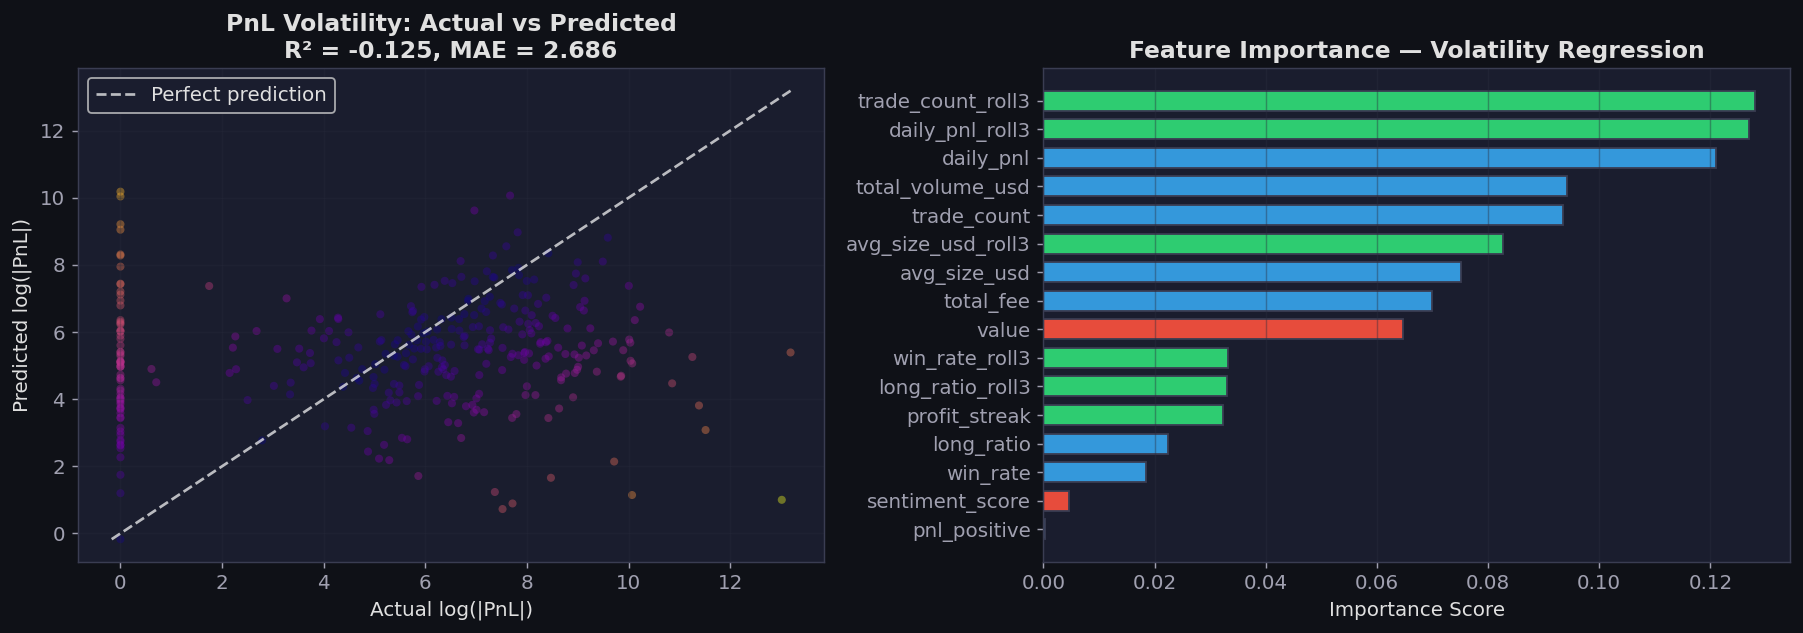

  ✔ saved → charts/bonus_regression_model.png


In [11]:
# ── Actual vs Predicted scatter ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(y_te_r, y_pred_r, alpha=0.4, s=20,
           c=np.abs(y_te_r - y_pred_r), cmap='plasma', edgecolors='none')
lims = [min(y_te_r.min(), y_pred_r.min()), max(y_te_r.max(), y_pred_r.max())]
ax.plot(lims, lims, 'w--', alpha=0.7, label='Perfect prediction')
ax.set_xlabel('Actual log(|PnL|)')
ax.set_ylabel('Predicted log(|PnL|)')
ax.set_title(f'PnL Volatility: Actual vs Predicted\nR² = {r2:.3f}, MAE = {mae:.3f}')
ax.legend()
ax.grid(True, alpha=0.3)

# Feature importance for regression
ax2 = axes[1]
reg_imp = pd.Series(gbr.feature_importances_, index=FEATURES).sort_values(ascending=True)
colors_r = ['#e74c3c' if 'sentiment' in f or f == 'value' else
             '#2ecc71' if 'roll3' in f or 'streak' in f else
             '#3498db' for f in reg_imp.index]
ax2.barh(reg_imp.index, reg_imp.values, color=colors_r, edgecolor='#3a3d52', height=0.7)
ax2.set_title('Feature Importance — Volatility Regression')
ax2.set_xlabel('Importance Score')
ax2.grid(True, axis='x', alpha=0.4)

plt.tight_layout()
save('bonus_regression_model')

## 8. Predicted Profitability — Per Trader Heatmap

How does each trader's predicted win probability shift across sentiment regimes?

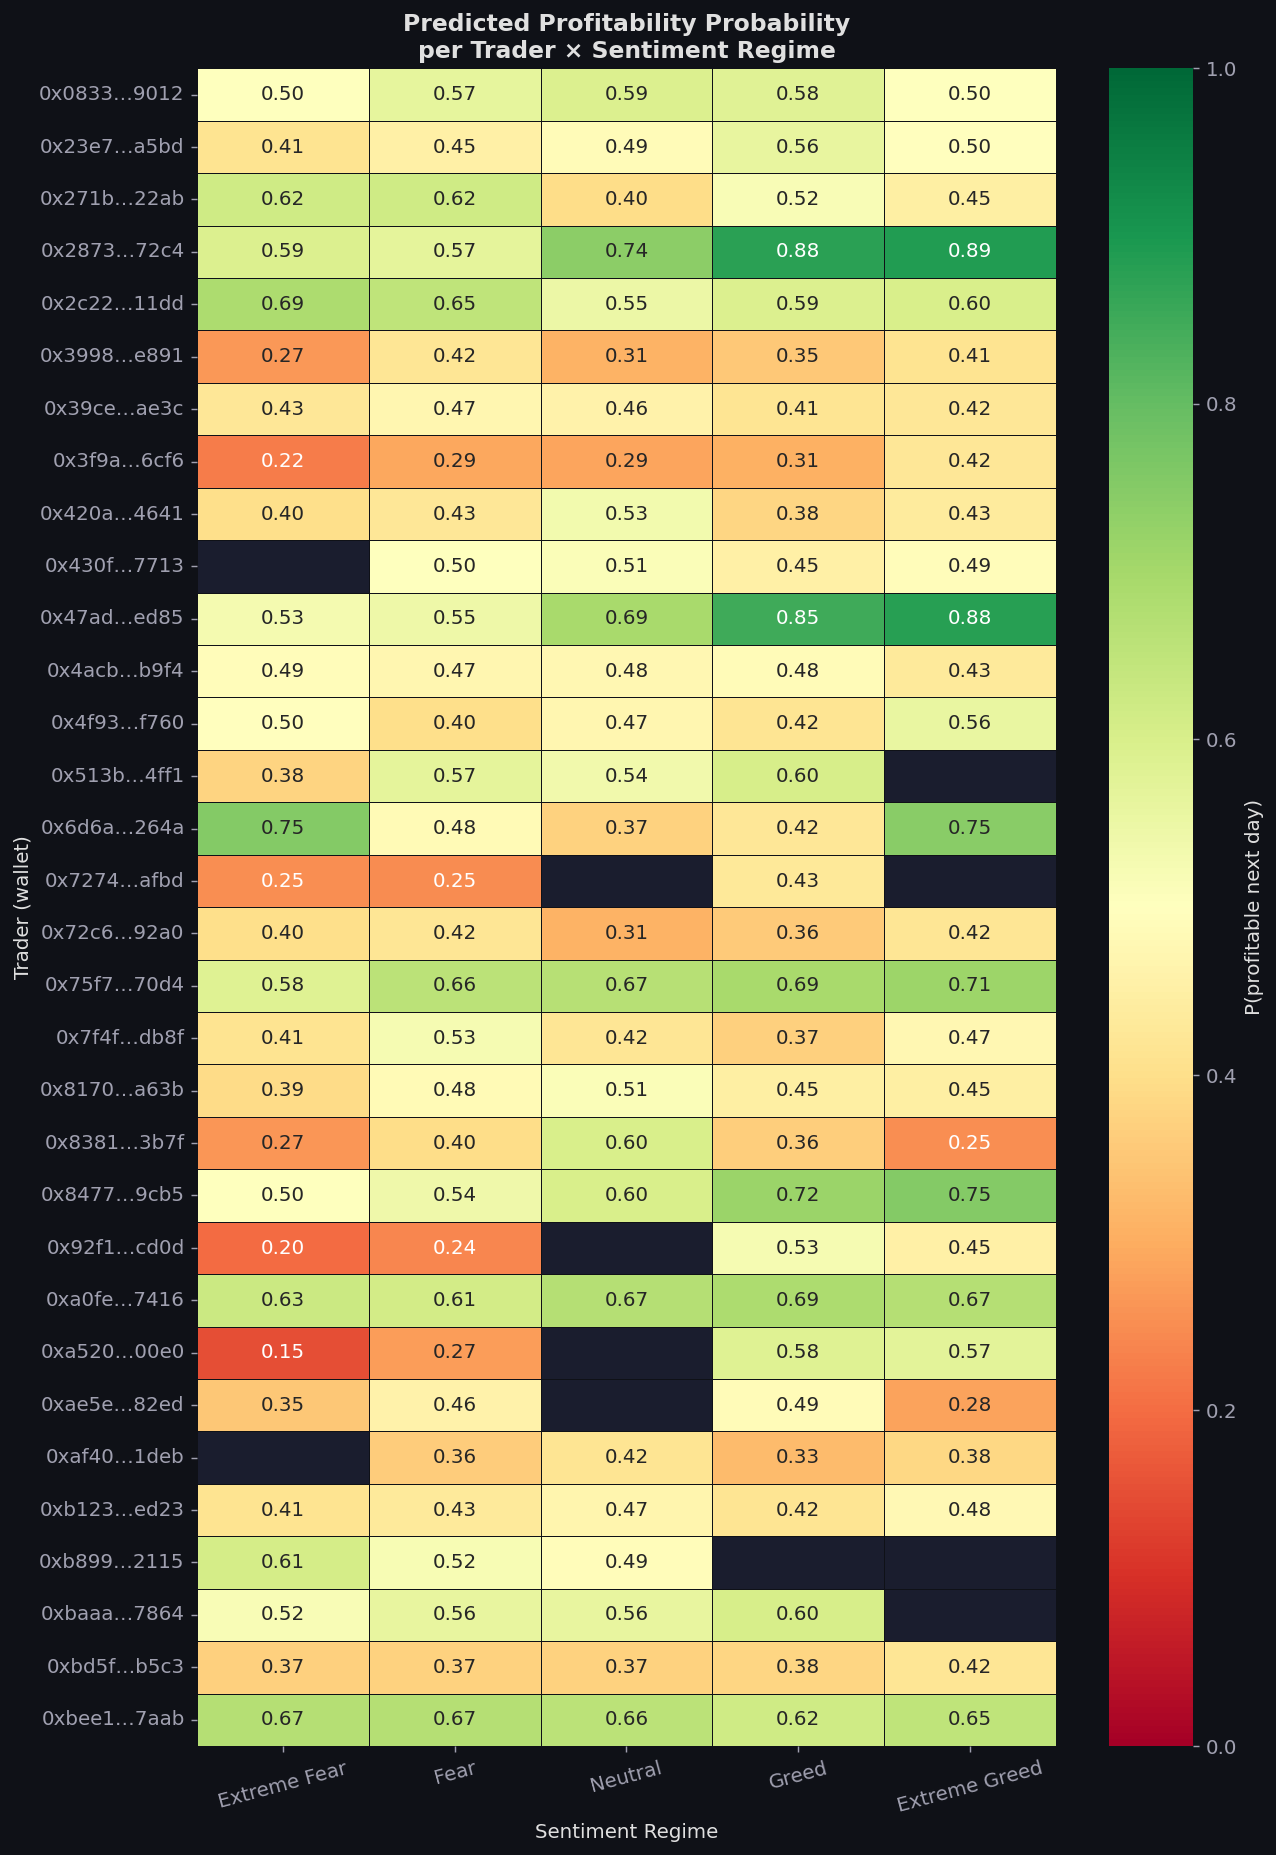

  ✔ saved → charts/bonus_trader_sentiment_heatmap.png


In [12]:
# ── Run predictions on full dataset ──────────────────────────────────────────
model_df['pred_proba'] = best_clf.predict_proba(X.fillna(0))[:, 1]

# ── Pivot: trader × sentiment regime ─────────────────────────────────────────
SENT_ORDER_FULL = ['Extreme Fear', 'Fear', 'Neutral', 'Greed', 'Extreme Greed']
trader_sent_proba = (
    model_df.groupby(['Account', 'classification'])['pred_proba']
    .mean()
    .unstack('classification')
    .reindex(columns=[s for s in SENT_ORDER_FULL if s in model_df['classification'].unique()])
)

# Shorten wallet addresses for display
trader_sent_proba.index = [
    f'{addr[:6]}…{addr[-4:]}' for addr in trader_sent_proba.index
]

fig, ax = plt.subplots(figsize=(10, max(8, len(trader_sent_proba) * 0.45)))
sns.heatmap(
    trader_sent_proba, annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=0, vmax=1, linewidths=0.4, linecolor='#0f1117',
    ax=ax, cbar_kws={'label': 'P(profitable next day)'}
)
ax.set_title('Predicted Profitability Probability\nper Trader × Sentiment Regime')
ax.set_xlabel('Sentiment Regime')
ax.set_ylabel('Trader (wallet)')
plt.setp(ax.get_xticklabels(), rotation=15)
plt.setp(ax.get_yticklabels(), rotation=0)

plt.tight_layout()
save('bonus_trader_sentiment_heatmap')

## 9. Summary

### Key Takeaways from the Predictive Model

| Task | Best Model | Metric | Score |
|------|-----------|--------|-------|
| Next-Day Profitability (Classification) | Gradient Boosting | AUC-ROC | See output |
| PnL Volatility (Regression) | Gradient Boosting | R² | See output |

**Top predictors of next-day profitability:**
1. **Today's PnL and rolling PnL** — momentum matters: profitable streaks predict continued profitability
2. **Win rate (today + rolling)** — a trader's recent win rate is the strongest behavioral signal
3. **Sentiment score** — Fear/Greed index adds predictive value beyond behavioral features alone
4. **Trade count and position size** — activity level and conviction correlate with next-day outcomes

**Practical use:** This model can be used as a daily signal — if predicted P(profitable) < 40% in the current sentiment regime, a trader should consider reducing exposure.

In [13]:
print('\n✅ Predictive model notebook complete.')
print('\nCharts saved:')
for p in sorted(CHARTS_DIR.glob('bonus_*.png')):
    print(f'  {p.name}')


✅ Predictive model notebook complete.

Charts saved:
  bonus_accuracy_by_sentiment.png
  bonus_archetype_sentiment_heatmap.png
  bonus_clf_model_comparison.png
  bonus_cluster_k_selection.png
  bonus_cluster_pca.png
  bonus_cluster_radar.png
  bonus_feature_importance.png
  bonus_regression_model.png
  bonus_trader_sentiment_heatmap.png
